# Лабораторна робота №8
## Тема: Самостійне моделювання на даних із зовнішніх джерел

- **Студент:** Адамчук Ярослав
- **Група:** МІТ-31
- **Номер у списку / Варіант:** 2
- **Датасет:** Energy Efficiency Dataset (UCI Machine Learning Repository, CC BY 4.0)
- **Цільова змінна ($y$):** `Y1` (Heating Load, навантаження на опалення, кВт·год/м²)
- **Ознаки ($X$):** $X_1 - X_8$ (геометричні параметри будівлі); стовпець $Y_2$ вилучено
- **Тип задачі:** Регресія (одномірна неперервна числова величина)
- **Фіксований SEED:** 42

In [2]:
import os
import sys
import json
import urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Фіксація параметрів відтворюваності
SEED = 42
keras.utils.set_random_seed(SEED)
np.random.seed(SEED)

# Створення директорій
data_dir = Path("data")
artifacts_dir = Path("artifacts")
figures_dir = Path("figures")

for d in [data_dir, artifacts_dir, figures_dir]:
    d.mkdir(parents=True, exist_ok=True)

print("Версії середовища:")
print(f"Python:     {sys.version.split()[0]}")
print(f"TensorFlow: {tf.__version__}")
print(f"NumPy:      {np.__version__}")
print(f"Pandas:     {pd.__version__}")
print("Директорії data, artifacts, figures успішно створені!")

Версії середовища:
Python:     3.11.9
TensorFlow: 2.21.0
NumPy:      2.4.6
Pandas:     3.1.1
Директорії data, artifacts, figures успішно створені!


In [8]:
# Автоматичне завантаження офіційного файлу ENB2012_data.xlsx з репозиторію UCI
data_path = data_dir / "ENB2012_data.xlsx"
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00242/ENB2012_data.xlsx"

if not data_path.exists():
    print(f"Завантаження {url}...")
    urllib.request.urlretrieve(url, data_path)
    print("Завантаження завершено.")
else:
    print("Файл даних уже присутній локально.")

# Читання Excel
df_raw = pd.read_excel(data_path)

# Перейменування стовпців відповідно до документації UCI
columns_map = {
    "X1": "Relative_Compactness",
    "X2": "Surface_Area",
    "X3": "Wall_Area",
    "X4": "Roof_Area",
    "X5": "Overall_Height",
    "X6": "Orientation",
    "X7": "Glazing_Area",
    "X8": "Glazing_Area_Distribution",
    "Y1": "Heating_Load",
    "Y2": "Cooling_Load"
}
df_raw = df_raw.rename(columns=columns_map)

print(f"Розмірність датасету: {df_raw.shape}")
print(f"Кількість пропусків:\n{df_raw.isna().sum()}")
display(df_raw.head())

Файл даних уже присутній локально.
Розмірність датасету: (768, 10)
Кількість пропусків:
Relative_Compactness         0
Surface_Area                 0
Wall_Area                    0
Roof_Area                    0
Overall_Height               0
Orientation                  0
Glazing_Area                 0
Glazing_Area_Distribution    0
Heating_Load                 0
Cooling_Load                 0
dtype: int64


,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution,Heating_Load,Cooling_Load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [9]:
# Цільова змінна — Heating_Load (Y1)
# Y2 (Cooling_Load) ВИЛУЧАЄМО, щоб не допустити витоку даних
target_col = "Heating_Load"
drop_cols = ["Heating_Load", "Cooling_Load"]

X = df_raw.drop(columns=drop_cols)
y = df_raw[target_col].copy()

feature_names = list(X.columns)
print(f"Ознаки для моделювання ({len(feature_names)}): {feature_names}")
print(f"Цільова змінна: {target_col}")

# Перевірка дублікатів
duplicates_count = X.duplicated().sum()
print(f"Кількість повних дублікатів за ознаками: {duplicates_count}")

Ознаки для моделювання (8): ['Relative_Compactness', 'Surface_Area', 'Wall_Area', 'Roof_Area', 'Overall_Height', 'Orientation', 'Glazing_Area', 'Glazing_Area_Distribution']
Цільова змінна: Heating_Load
Кількість повних дублікатів за ознаками: 0


In [5]:
indices = np.arange(len(X))

# Перший етап: 70% на train, 30% на dev (val + test)
train_idx, dev_idx = train_test_split(indices, test_size=0.30, random_state=SEED)

# Другий етап: 30% dev ділимо порівну -> 15% validation, 15% test
val_idx, test_idx = train_test_split(dev_idx, test_size=0.50, random_state=SEED)

# Перевірка на відсутність перетинів індексів
assert len(set(train_idx).intersection(set(val_idx))) == 0
assert len(set(train_idx).intersection(set(test_idx))) == 0
assert len(set(val_idx).intersection(set(test_idx))) == 0

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

print(f"Train розмір: {X_train.shape} (70%)")
print(f"Val розмір:   {X_val.shape} (15%)")
print(f"Test розмір:  {X_test.shape} (15%)")

Train розмір: (537, 8) (70%)
Val розмір:   (115, 8) (15%)
Test розмір:  (116, 8) (15%)


In [6]:
numeric_features = feature_names

preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_features)
    ]
)

# Навчаємося ТІЛЬКИ на X_train; до val і test застосовуємо лише transform
X_train_prep = preprocessor.fit_transform(X_train).astype("float32")
X_val_prep = preprocessor.transform(X_val).astype("float32")
X_test_prep = preprocessor.transform(X_test).astype("float32")

# Зберігаємо об'єкт препроцесора
joblib.dump(preprocessor, artifacts_dir / "preprocessor.joblib")

assert np.isfinite(X_train_prep).all()
assert np.isfinite(X_val_prep).all()
assert np.isfinite(X_test_prep).all()
print("Препроцесор навчено на train та збережено в artifacts/preprocessor.joblib.")

Препроцесор навчено на train та збережено в artifacts/preprocessor.joblib.


In [11]:
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {"MAE": mae, "RMSE": rmse, "R2": r2}

# 1. DummyRegressor за середнім значенням
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train_prep, y_train)
dummy_val_preds = dummy.predict(X_val_prep)
dummy_val_m = regression_metrics(y_val, dummy_val_preds)
print("DummyRegressor (Val):", dummy_val_m)

# 2. LinearRegression
lin_reg = LinearRegression()
lin_reg.fit(X_train_prep, y_train)
lin_val_preds = lin_reg.predict(X_val_prep)
lin_val_m = regression_metrics(y_val, lin_val_preds)
print("LinearRegression (Val):", lin_val_m)

DummyRegressor (Val): {'MAE': 9.224525625455428, 'RMSE': np.float64(10.307680137313175), 'R2': -0.039457854341793386}
LinearRegression (Val): {'MAE': 2.2387936855813733, 'RMSE': np.float64(3.161488129638837), 'R2': 0.9022159254911426}


In [12]:
keras.utils.set_random_seed(SEED)

def build_base_nn(input_dim):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(32, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(1)  # Регресія: один вихід без активації
    ], name="NN_Base_32units")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="mean_squared_error",
        metrics=[keras.metrics.RootMeanSquaredError(name="rmse"), keras.metrics.MeanAbsoluteError(name="mae")]
    )
    return model

nn_base = build_base_nn(X_train_prep.shape[1])
nn_base.summary()

checkpoint_base = "artifacts/nn_base_best.keras"
callbacks_base = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(checkpoint_base, monitor="val_loss", save_best_only=True)
]

print("\n--- Навчання базової нейромережі ---")
history_base = nn_base.fit(
    X_train_prep, y_train.values,
    validation_data=(X_val_prep, y_val.values),
    epochs=200,
    batch_size=64,
    callbacks=callbacks_base,
    verbose=1
)

best_base_nn = keras.models.load_model(checkpoint_base)
base_nn_val_preds = best_base_nn.predict(X_val_prep, verbose=0).flatten()
base_nn_val_m = regression_metrics(y_val, base_nn_val_preds)
print("\nBase NN Val Metrics:", base_nn_val_m)

Model: "NN_Base_32units"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,377 (5.38 KB)

 Trainable params: 1,377 (5.38 KB)

 Non-trainable params: 0 (0.00 B)


--- Навчання базової нейромережі ---
Epoch 1/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 588.6780 - mae: 22.0230 - rmse: 24.2627 - val_loss: 671.5884 - val_mae: 23.8306 - val_rmse: 25.9150
Epoch 2/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 572.2051 - mae: 21.6626 - rmse: 23.9208 - val_loss: 652.8997 - val_mae: 23.4479 - val_rmse: 25.5519
Epoch 3/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 555.7487 - mae: 21.2941 - rmse: 23.5743 - val_loss: 633.2405 - val_mae: 23.0396 - val_rmse: 25.1643
Epoch 4/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 537.9366 - mae: 20.8904 - rmse: 23.1935 - val_loss: 611.3724 - val_mae: 22.5786 - val_rmse: 24.7259
Epoch 5/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 517.7994 - mae: 20.4285 - rmse: 22.7552 - val_loss: 586.1166 - val_mae: 22.0395 - val_rmse: 24.2098
Epoch 6/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 494.3293 - mae: 19.8842 - rmse: 22.2335 - val_loss: 556.4376 - val_mae: 21.3962 - val_rmse: 23.5889
Epoch 7/200
9/

In [13]:
keras.utils.set_random_seed(SEED)

def build_improved_nn(input_dim):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(1)
    ], name="NN_Improved_64units")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="mean_squared_error",
        metrics=[keras.metrics.RootMeanSquaredError(name="rmse"), keras.metrics.MeanAbsoluteError(name="mae")]
    )
    return model

nn_improved = build_improved_nn(X_train_prep.shape[1])
nn_improved.summary()

checkpoint_improved = "artifacts/nn_improved_best.keras"
callbacks_improved = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(checkpoint_improved, monitor="val_loss", save_best_only=True)
]

print("\n--- Навчання покращеної нейромережі ---")
history_improved = nn_improved.fit(
    X_train_prep, y_train.values,
    validation_data=(X_val_prep, y_val.values),
    epochs=200,
    batch_size=64,
    callbacks=callbacks_improved,
    verbose=1
)

best_improved_nn = keras.models.load_model(checkpoint_improved)
improved_nn_val_preds = best_improved_nn.predict(X_val_prep, verbose=0).flatten()
improved_nn_val_m = regression_metrics(y_val, improved_nn_val_preds)
print("\nImproved NN Val Metrics:", improved_nn_val_m)

Model: "NN_Improved_64units"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,801 (18.75 KB)

 Trainable params: 4,801 (18.75 KB)

 Non-trainable params: 0 (0.00 B)


--- Навчання покращеної нейромережі ---
Epoch 1/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 578.7696 - mae: 21.8411 - rmse: 24.0576 - val_loss: 649.1405 - val_mae: 23.4032 - val_rmse: 25.4782
Epoch 2/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 547.4729 - mae: 21.1404 - rmse: 23.3981 - val_loss: 612.3598 - val_mae: 22.6346 - val_rmse: 24.7459
Epoch 3/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 513.6772 - mae: 20.3710 - rmse: 22.6644 - val_loss: 568.9994 - val_mae: 21.7087 - val_rmse: 23.8537
Epoch 4/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 472.4113 - mae: 19.4113 - rmse: 21.7350 - val_loss: 513.2551 - val_mae: 20.4804 - val_rmse: 22.6551
Epoch 5/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 419.4746 - mae: 18.1381 - rmse: 20.4811 - val_loss: 442.9782 - val_mae: 18.8415 - val_rmse: 21.0470
Epoch 6/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 354.4926 - mae: 16.4691 - rmse: 18.8280 - val_loss: 360.3964 - val_mae: 16.7433 - val_rmse: 18.9841
Epoch 7/200

In [14]:
print(f"Base NN Val RMSE:     {base_nn_val_m['RMSE']:.4f}")
print(f"Improved NN Val RMSE: {improved_nn_val_m['RMSE']:.4f}")

# Обираємо за мінімумом val RMSE
if improved_nn_val_m["RMSE"] < base_nn_val_m["RMSE"]:
    selected_nn_name = "NN_Improved (64 units)"
    selected_nn = best_improved_nn
    hypothesis_result = "Підтверджена (розширення шарів зменшило RMSE)"
else:
    selected_nn_name = "NN_Base (32 units)"
    selected_nn = best_base_nn
    hypothesis_result = "Не підтверджена (залишено базову архітектуру)"

print(f"\n--> Фінально обрана нейромережа: {selected_nn_name}")

# Тестування на test (1 раз)
dummy_test_preds = dummy.predict(X_test_prep)
lin_test_preds = lin_reg.predict(X_test_prep)
base_test_preds = best_base_nn.predict(X_test_prep, verbose=0).flatten()
improved_test_preds = best_improved_nn.predict(X_test_prep, verbose=0).flatten()

comparison_df = pd.DataFrame([
    {
        "Модель": "DummyRegressor (mean)",
        "Val RMSE (критерій)": dummy_val_m["RMSE"],
        "Val MAE": dummy_val_m["MAE"],
        "Val R2": dummy_val_m["R2"],
        "Test RMSE": regression_metrics(y_test, dummy_test_preds)["RMSE"],
        "Test MAE": regression_metrics(y_test, dummy_test_preds)["MAE"],
        "Test R2": regression_metrics(y_test, dummy_test_preds)["R2"],
        "Епох": 0
    },
    {
        "Модель": "LinearRegression",
        "Val RMSE (критерій)": lin_val_m["RMSE"],
        "Val MAE": lin_val_m["MAE"],
        "Val R2": lin_val_m["R2"],
        "Test RMSE": regression_metrics(y_test, lin_test_preds)["RMSE"],
        "Test MAE": regression_metrics(y_test, lin_test_preds)["MAE"],
        "Test R2": regression_metrics(y_test, lin_test_preds)["R2"],
        "Епох": 0
    },
    {
        "Модель": "NN_Base (32-32)",
        "Val RMSE (критерій)": base_nn_val_m["RMSE"],
        "Val MAE": base_nn_val_m["MAE"],
        "Val R2": base_nn_val_m["R2"],
        "Test RMSE": regression_metrics(y_test, base_test_preds)["RMSE"],
        "Test MAE": regression_metrics(y_test, base_test_preds)["MAE"],
        "Test R2": regression_metrics(y_test, base_test_preds)["R2"],
        "Епох": len(history_base.history["loss"])
    },
    {
        "Модель": "NN_Improved (64-64)",
        "Val RMSE (критерій)": improved_nn_val_m["RMSE"],
        "Val MAE": improved_nn_val_m["MAE"],
        "Val R2": improved_nn_val_m["R2"],
        "Test RMSE": regression_metrics(y_test, improved_test_preds)["RMSE"],
        "Test MAE": regression_metrics(y_test, improved_test_preds)["MAE"],
        "Test R2": regression_metrics(y_test, improved_test_preds)["R2"],
        "Епох": len(history_improved.history["loss"])
    }
])

comparison_df.to_csv(artifacts_dir / "model_comparison.csv", index=False)
display(comparison_df)

Base NN Val RMSE:     2.4738
Improved NN Val RMSE: 2.3059

--> Фінально обрана нейромережа: NN_Improved (64 units)


,Модель,Val RMSE (критерій),Val MAE,Val R2,Test RMSE,Test MAE,Test R2,Епох
0,DummyRegressor (mean),10.307680,9.224526,-0.039458,9.901450,9.016207,-0.000867,0
1,LinearRegression,3.161488,2.238794,0.902216,2.773804,2.072255,0.921453,0
2,NN_Base (32-32),2.473845,1.860615,0.940127,1.915468,1.392115,0.962543,200
3,NN_Improved (64-64),2.305886,1.657236,0.947981,1.921483,1.357421,0.962308,200


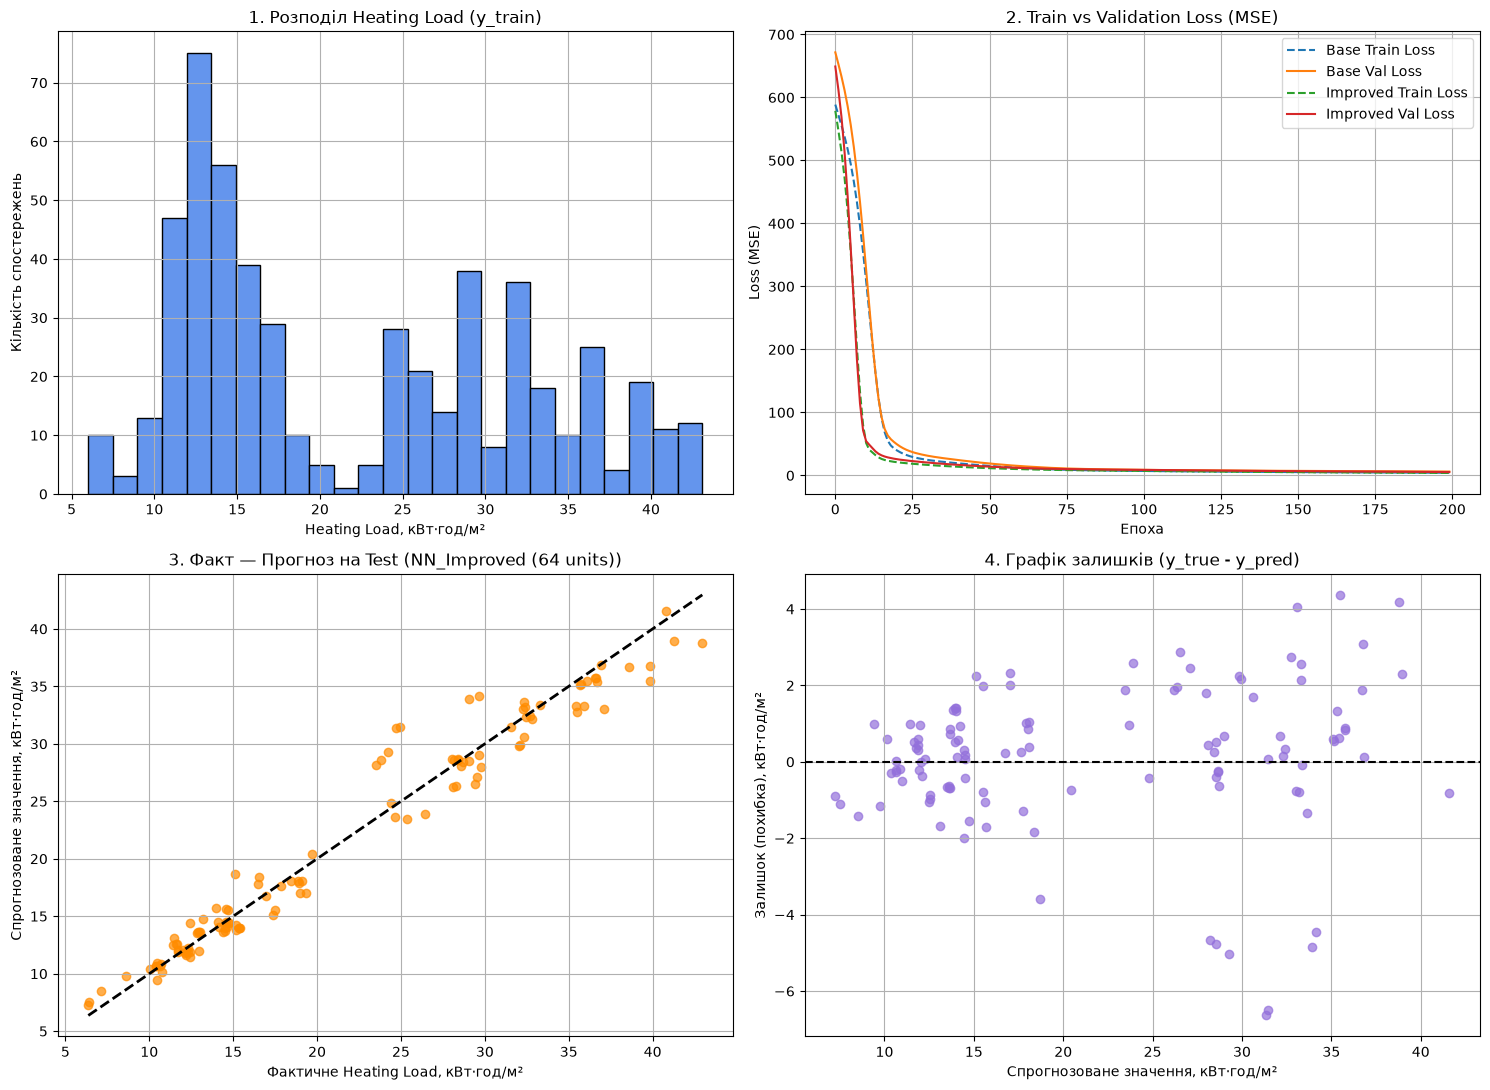

In [15]:
final_test_preds = selected_nn.predict(X_test_prep, verbose=0).flatten()
residuals = y_test.values - final_test_preds

test_preds_df = pd.DataFrame({
    "y_true": y_test.values,
    "y_pred": final_test_preds,
    "residual": residuals,
    "abs_error": np.abs(residuals)
})
test_preds_df.to_csv(artifacts_dir / "test_predictions.csv", index=False)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Розподіл цілі на train
axes[0, 0].hist(y_train, bins=25, color="cornflowerblue", edgecolor="black")
axes[0, 0].set_title("1. Розподіл Heating Load (y_train)")
axes[0, 0].set_xlabel("Heating Load, кВт·год/м²")
axes[0, 0].set_ylabel("Кількість спостережень")
axes[0, 0].grid(True)

# 2. Динаміка навчання
axes[0, 1].plot(history_base.history["loss"], label="Base Train Loss", linestyle="--")
axes[0, 1].plot(history_base.history["val_loss"], label="Base Val Loss")
axes[0, 1].plot(history_improved.history["loss"], label="Improved Train Loss", linestyle="--")
axes[0, 1].plot(history_improved.history["val_loss"], label="Improved Val Loss")
axes[0, 1].set_title("2. Train vs Validation Loss (MSE)")
axes[0, 1].set_xlabel("Епоха")
axes[0, 1].set_ylabel("Loss (MSE)")
axes[0, 1].legend()
axes[0, 1].grid(True)

# 3. Факт — Прогноз
axes[1, 0].scatter(y_test, final_test_preds, alpha=0.7, color="darkorange")
axes[1, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "k--", lw=2)
axes[1, 0].set_title(f"3. Факт — Прогноз на Test ({selected_nn_name})")
axes[1, 0].set_xlabel("Фактичне Heating Load, кВт·год/м²")
axes[1, 0].set_ylabel("Спрогнозоване значення, кВт·год/м²")
axes[1, 0].grid(True)

# 4. Графік залишків
axes[1, 1].scatter(final_test_preds, residuals, alpha=0.7, color="mediumpurple")
axes[1, 1].axhline(0, color="black", linestyle="--", lw=1.5)
axes[1, 1].set_title("4. Графік залишків (y_true - y_pred)")
axes[1, 1].set_xlabel("Спрогнозоване значення, кВт·год/м²")
axes[1, 1].set_ylabel("Залишок (похибка), кВт·год/м²")
axes[1, 1].grid(True)

plt.tight_layout()
plt.savefig(figures_dir / "regression_analysis_plots.png", dpi=300)
plt.show()

In [18]:
# 1. Знаходимо позиційні індекси 5 найбільших помилок у test_preds_df
worst_pos_idx = test_preds_df["abs_error"].nlargest(5).index

# 2. Витягуємо відповідні рядки з X_test через iloc
worst_cases = X_test.iloc[worst_pos_idx].copy().reset_index(drop=True)

# 3. Додаємо факт, прогноз та помилку
worst_cases["Факт (y_true)"] = test_preds_df.loc[worst_pos_idx, "y_true"].values
worst_cases["Прогноз (y_pred)"] = test_preds_df.loc[worst_pos_idx, "y_pred"].values
worst_cases["Абсолютна помилка"] = test_preds_df.loc[worst_pos_idx, "abs_error"].values

print("Топ-5 найбільших абсолютних помилок моделі на тесті:")
display(worst_cases)

Топ-5 найбільших абсолютних помилок моделі на тесті:


,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution,Факт (y_true),Прогноз (y_pred),Абсолютна помилка
0,0.82,612.5,318.5,147.0,7.0,2,0.25,3,24.70,31.338099,6.638099
1,0.82,612.5,318.5,147.0,7.0,5,0.25,2,24.94,31.446190,6.506190
2,0.82,612.5,318.5,147.0,7.0,3,0.10,2,24.23,29.271564,5.041564
3,0.82,612.5,318.5,147.0,7.0,4,0.40,5,29.06,33.918755,4.858755
4,0.82,612.5,318.5,147.0,7.0,2,0.10,4,23.80,28.558346,4.758346


In [17]:
# 1. Збереження моделі
model_save_path = artifacts_dir / "lab8_model.keras"
selected_nn.save(model_save_path)
print(f"Модель успішно збережено в: {model_save_path}")

# 2. Збереження metadata.json
metadata = {
    "source": "UCI Machine Learning Repository",
    "dataset_name": "Energy Efficiency Dataset",
    "file": "ENB2012_data.xlsx",
    "target": target_col,
    "target_units": "kWh/m^2",
    "task_type": "Regression",
    "excluded_columns": drop_cols,
    "feature_names": feature_names,
    "seed": SEED,
    "split_ratio": "70/15/15",
    "train_size": len(train_idx),
    "val_size": len(val_idx),
    "test_size": len(test_idx),
    "hypothesis": "Збільшення ширини шарів з 32 до 64 нейронів",
    "hypothesis_result": hypothesis_result,
    "selected_model": selected_nn_name,
    "packages": {
        "python": sys.version.split()[0],
        "tensorflow": tf.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__
    }
}

with open(artifacts_dir / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=4)
print("Файл metadata.json збережено.")

# 3. Перевірка відновлення пайплайну на 3 «сирих» тестових рядках
raw_probe = X_test.iloc[:3]
true_probe = y_test.iloc[:3].values

probe_prep_before = preprocessor.transform(raw_probe).astype("float32")
preds_before = selected_nn.predict(probe_prep_before, verbose=0).flatten()

restored_preprocessor = joblib.load(artifacts_dir / "preprocessor.joblib")
restored_model = keras.models.load_model(model_save_path)

probe_prep_after = restored_preprocessor.transform(raw_probe).astype("float32")
preds_after = restored_model.predict(probe_prep_after, verbose=0).flatten()

np.testing.assert_allclose(preds_before, preds_after, rtol=1e-5, atol=1e-6)
print("Assert пройдено: збережений та відновлений пайплайни дають ідентичні результати!")

for i in range(3):
    print(f"Об'єкт {i+1}: Факт = {true_probe[i]:.2f}, Прогноз = {preds_after[i]:.2f}")

Модель успішно збережено в: artifacts\lab8_model.keras
Файл metadata.json збережено.
Assert пройдено: збережений та відновлений пайплайни дають ідентичні результати!
Об'єкт 1: Факт = 24.94, Прогноз = 31.45
Об'єкт 2: Факт = 35.45, Прогноз = 33.30
Об'єкт 3: Факт = 28.07, Прогноз = 28.71
